# Logistic regression baseline (modelling plan, Phase 4)

The simple model to compare LightGBM against. Same rows, same label, same three temporal folds and the same metrics
as `05_lgbm_baseline.ipynb`, so the two can sit in one results table. Everything is in this notebook.

| § | What |
|---|---|
| 0 | Setup |
| 1 | Build the account-week table |
| 2 | Prepare the weekly features (fitted inside each fold) |
| 3 | Train and score: 3 folds × 3 views |
| 4 | Results |
| 5 | Figures |
| 6 | Coefficients |
| 7 | Compare with LightGBM, save |

**Rules kept.** Labels only through `amldata.labels()`; months 0 to 4 only; no hidden file is read.

In [1]:
from __future__ import annotations
import os, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
if "ipykernel" not in sys.modules:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

ROOT = Path.cwd().resolve()
while not (ROOT / "src" / "amldata").is_dir():
    if ROOT.parent == ROOT:
        raise FileNotFoundError("start this notebook from inside the aml-detection-system repo")
    ROOT = ROOT.parent
os.chdir(ROOT)
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import amldata
from features import weekly
from features.weekly import FEATURES as WEEKLY

OUT = os.environ.get("EDA_DATA", amldata.DEFAULT_OUT)      # data/v1_full; "data/v1" for a quick run
RUN = os.path.basename(os.path.normpath(OUT))
REPORT = Path(os.environ.get("EDA_REPORT", f"outputs/modelling/models/{RUN}/logreg_baseline"))
REPORT.mkdir(parents=True, exist_ok=True)
WEEKS = (0, 26)
FOLDS = [((0, 1), 2), ((0, 1, 2), 3), ((0, 1, 2, 3), 4)]
KEY = ["account_id", "weeks_since_open"]
COLORS = {"application": "#eb6834", "activity": "#2a78d6", "combined": "#1baf7a"}
print(f"data {OUT} -> report {REPORT}")

data data/v1_full -> report outputs/modelling/models/v1_full/logreg_baseline


## 1. The account-week table

Same as the LightGBM notebook except the application part: logistic regression reads
`features/accounts_linear.parquet` (**56 columns**: missing codes filled with the median plus a flag, skewed columns
logged, categories one-hot encoded, continuous columns standardised). That file was fitted on months 0 to 4 by
`02_preprocess.ipynb`. Label `mule_by_day`; weeks after the bank closed the account are dropped.

In [2]:
t0 = time.time()
lin = pd.read_parquet(Path(OUT) / "features" / "accounts_linear.parquet")
lin = lin[lin["open_month"].isin(range(5))].reset_index(drop=True)
APP = [c for c in lin.columns if c not in ("account_id", "open_month")]
for c in APP:
    lin[c] = lin[c].astype("float32")

wk = weekly.load(OUT, WEEKS, months=tuple(range(5)))    # checks the manifest; rows sorted, so every run fits alike

lab = pd.concat([amldata.labels(OUT, months=range(5), weeks_since_open=w)
                 [["account_id", "open_month", "mule_by_day", "open_by_day"]].assign(weeks_since_open=w)
                 for w in range(WEEKS[0], WEEKS[1] + 1)], ignore_index=True)
df = wk.merge(lab, on=KEY, validate="1:1").merge(lin.drop(columns="open_month"), on="account_id", validate="m:1")
df = df[df["open_by_day"] == 1].drop(columns="open_by_day").reset_index(drop=True)
prof = amldata.labels(OUT, months=range(5), profile=True).set_index("account_id")["profile"]  # breakdown only
print(f"{len(df):,} account-weeks, {int(df.mule_by_day.sum()):,} mule weeks, {len(APP)} application columns, "
      f"{time.time() - t0:.0f}s")

4,449,169 account-weeks, 8,327 mule weeks, 56 application columns, 5s


## 2. Preparing the weekly features

The 28 weekly features are raw values (pounds, counts, shares, some empty), which a linear model handles badly.
Three steps, **fitted on each fold's training months only** so nothing leaks from the validation month:

| group | columns | steps |
|---|---|---|
| amounts and counts (long right tail) | money, counts, maxima, running totals, peer ratio, minutes | fill empty with median (+ flag) → $\log(1+x)$ → standardise |
| shares between 0 and 1 | pass-through, speed shares, new-payer share, cumulative mix | fill empty with median (+ flag) → standardise |
| self vs past (z-scores, can be negative) | 3 columns | fill → clip to $[-10, 10]$ → standardise |
| week number | `weeks_since_open` | standardise |

The application columns are already prepared, so they pass through unchanged.

In [3]:
SHARES = ["new_payer_share_wk", "passthrough_wk", "out_1h_share_wk", "out_24h_share_wk",
          "internal_out_share_cum", "cash_in_share_cum", "abroad_out_share_cum", "high_risk_out_share_cum"]
ZSCORE = ["self_vs_past_money_in", "self_vs_past_payers", "self_vs_past_rows"]
LOGGED = [c for c in WEEKLY if c not in SHARES + ZSCORE]

def weekly_prep(app_cols):
    log = make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                        FunctionTransformer(lambda x: np.log1p(np.clip(x, 0, None)), feature_names_out="one-to-one"), StandardScaler())
    share = make_pipeline(SimpleImputer(strategy="median", add_indicator=True), StandardScaler())
    z = make_pipeline(SimpleImputer(strategy="median", add_indicator=True),
                      FunctionTransformer(lambda x: np.clip(x, -10, 10), feature_names_out="one-to-one"), StandardScaler())
    parts = [("log", log, LOGGED), ("share", share, SHARES), ("z", z, ZSCORE),
             ("week", StandardScaler(), ["weeks_since_open"])]
    if app_cols:
        parts.append(("app", "passthrough", app_cols))
    return parts

VIEWS = {"application": ([], APP), "activity": (WEEKLY, []), "combined": (WEEKLY, APP)}
print({v: f"{len(w) + (1 if w else 0)} weekly + {len(a)} application" for v, (w, a) in VIEWS.items()})

{'application': '0 weekly + 56 application', 'activity': '29 weekly + 0 application', 'combined': '29 weekly + 56 application'}


## 3. Train and score

`LogisticRegression(class_weight="balanced", max_iter=2000)`, L2 penalty with the default strength $C = 1$.
Class weights work as in the LightGBM notebook: a mule row weighs $\frac{1-p}{p}$ times a normal row.

Same three folds (train months 0-1 → validate 2, 0-2 → 3, 0-3 → 4). Fitting on the full 244k data takes a few
minutes per fold; use `data/v1` for a quick run.

In [4]:
def top_k(y, s, pct):
    k = max(1, int(round(pct * len(s))))
    flag = np.zeros(len(s), bool); flag[np.argsort(-s, kind="stable")[:k]] = True
    return prf(y, flag)

def prf(y, flag):
    tp = int((flag & (y == 1)).sum()); p = tp / max(flag.sum(), 1); r = tp / max(y.sum(), 1)
    return {"precision": p, "recall": r, "f1": 2 * p * r / (p + r) if p + r else 0.0}

def evaluate(valid, s):
    acc = valid.assign(s=s).groupby("account_id").agg(y=("mule_by_day", "max"), s=("s", "max"))
    y, sa = acc["y"].to_numpy(), acc["s"].to_numpy()
    pr, rc, th = precision_recall_curve(y, sa)
    f = np.where(pr + rc > 0, 2 * pr * rc / np.maximum(pr + rc, 1e-12), 0)[:-1]
    m = {"acc_roc_auc": roc_auc_score(y, sa), "acc_pr_auc": average_precision_score(y, sa),
         "accounts": len(acc), "account_mules": int(y.sum())}
    for tag, d in {"at_0.5": prf(y, sa >= 0.5), "best_f1": prf(y, sa >= th[np.argmax(f)]), "top_1%": top_k(y, sa, 0.01)}.items():
        m.update({f"acc_{tag}_{k}": v for k, v in d.items()})
    top = set(acc.index[np.argsort(-sa, kind="stable")[: max(1, int(round(0.01 * len(acc))))]])
    t = prof.reindex(acc.index[y == 1]).fillna("unknown")
    for typ in ("fake", "witting", "unwitting"):
        ids = t.index[t == typ]; m[f"top_1%_{typ}"] = f"{sum(a in top for a in ids)}/{len(ids)}"
    return m

rows, oof, coefs = [], [], []
for f, (tr_m, va_m) in enumerate(FOLDS, start=1):
    train, valid = df[df.open_month.isin(tr_m)], df[df.open_month == va_m]
    for view, (wcols, acols) in VIEWS.items():
        parts = weekly_prep(acols) if wcols else [("app", "passthrough", acols)]
        pipe = make_pipeline(ColumnTransformer(parts), LogisticRegression(class_weight="balanced", max_iter=2000))
        t1 = time.time()
        pipe.fit(train, train["mule_by_day"])
        s = pipe.predict_proba(valid)[:, 1]
        m = evaluate(valid, s)
        rows.append({"fold": f, "valid_month": va_m, "view": view, "fit_s": round(time.time() - t1), **m})
        oof.append(valid[KEY + ["mule_by_day"]].assign(score=s, view=view, fold=f))
        names = pipe[0].get_feature_names_out()
        coefs.append(pd.DataFrame({"feature": names, "coef": pipe[-1].coef_[0], "view": view, "fold": f}))
        print(f"fold {f} -> month {va_m} {view:12s} PR-AUC {m['acc_pr_auc']:.3f}  top-1% "
              f"P {m['acc_top_1%_precision']:.2f} R {m['acc_top_1%_recall']:.2f} F1 {m['acc_top_1%_f1']:.2f}  ({time.time() - t1:.0f}s)")
folds, oof, coefs = pd.DataFrame(rows), pd.concat(oof, ignore_index=True), pd.concat(coefs, ignore_index=True)

fold 1 -> month 2 application  PR-AUC 0.024  top-1% P 0.02 R 0.12 F1 0.04  (2s)


fold 1 -> month 2 activity     PR-AUC 0.048  top-1% P 0.06 R 0.30 F1 0.10  (7s)


fold 1 -> month 2 combined     PR-AUC 0.123  top-1% P 0.11 R 0.56 F1 0.18  (9s)


fold 2 -> month 3 application  PR-AUC 0.023  top-1% P 0.04 R 0.19 F1 0.06  (3s)


fold 2 -> month 3 activity     PR-AUC 0.025  top-1% P 0.04 R 0.21 F1 0.07  (10s)


fold 2 -> month 3 combined     PR-AUC 0.069  top-1% P 0.08 R 0.40 F1 0.13  (15s)


fold 3 -> month 4 application  PR-AUC 0.027  top-1% P 0.04 R 0.16 F1 0.06  (5s)


fold 3 -> month 4 activity     PR-AUC 0.041  top-1% P 0.07 R 0.29 F1 0.11  (15s)


fold 3 -> month 4 combined     PR-AUC 0.144  top-1% P 0.13 R 0.54 F1 0.21  (22s)


## 4. Results (account level, mean of 3 folds)

In [5]:
COLS = {"acc_roc_auc": "ROC-AUC", "acc_pr_auc": "PR-AUC", "acc_at_0.5_precision": "P @0.5", "acc_at_0.5_recall": "R @0.5",
        "acc_at_0.5_f1": "F1 @0.5", "acc_best_f1_precision": "P @best", "acc_best_f1_recall": "R @best",
        "acc_best_f1_f1": "F1 @best", "acc_top_1%_precision": "P top 1%", "acc_top_1%_recall": "R top 1%",
        "acc_top_1%_f1": "F1 top 1%"}
summary = folds.groupby("view", sort=False)[list(COLS)].mean().rename(columns=COLS)
summary.round(3)

,ROC-AUC,PR-AUC,P @0.5,R @0.5,F1 @0.5,P @best,R @best,F1 @best,P top 1%,R top 1%,F1 top 1%
view,,,,,,,,,,,
application,0.799,0.025,0.006,0.701,0.012,0.112,0.076,0.087,0.033,0.156,0.054
activity,0.919,0.038,0.002,0.991,0.005,0.067,0.246,0.104,0.056,0.267,0.092
combined,0.931,0.112,0.005,0.972,0.009,0.215,0.282,0.241,0.105,0.501,0.173


In [6]:
folds[["fold", "valid_month", "view", "accounts", "account_mules", "acc_pr_auc", "acc_top_1%_precision",
       "acc_top_1%_recall", "acc_top_1%_f1", "top_1%_fake", "top_1%_witting", "top_1%_unwitting"]].round(3)

,fold,valid_month,view,accounts,account_mules,acc_pr_auc,acc_top_1%_precision,acc_top_1%_recall,acc_top_1%_f1,top_1%_fake,top_1%_witting,top_1%_unwitting
0,1,2,application,33523,64,0.024,0.024,0.125,0.040,8/56,0/3,0/5
1,1,2,activity,33523,64,0.048,0.057,0.297,0.095,16/56,2/3,1/5
2,1,2,combined,33523,64,0.123,0.107,0.562,0.180,32/56,2/3,2/5
3,2,3,application,36724,70,0.023,0.035,0.186,0.059,13/57,0/7,0/6
4,2,3,activity,36724,70,0.025,0.041,0.214,0.069,11/57,1/7,3/6
5,2,3,combined,36724,70,0.069,0.076,0.400,0.128,26/57,0/7,2/6
6,3,4,application,31279,76,0.027,0.038,0.158,0.062,12/65,0/4,0/7
7,3,4,activity,31279,76,0.041,0.070,0.289,0.113,18/65,0/4,4/7
8,3,4,combined,31279,76,0.144,0.131,0.539,0.211,38/65,0/4,3/7


## 5. Figures

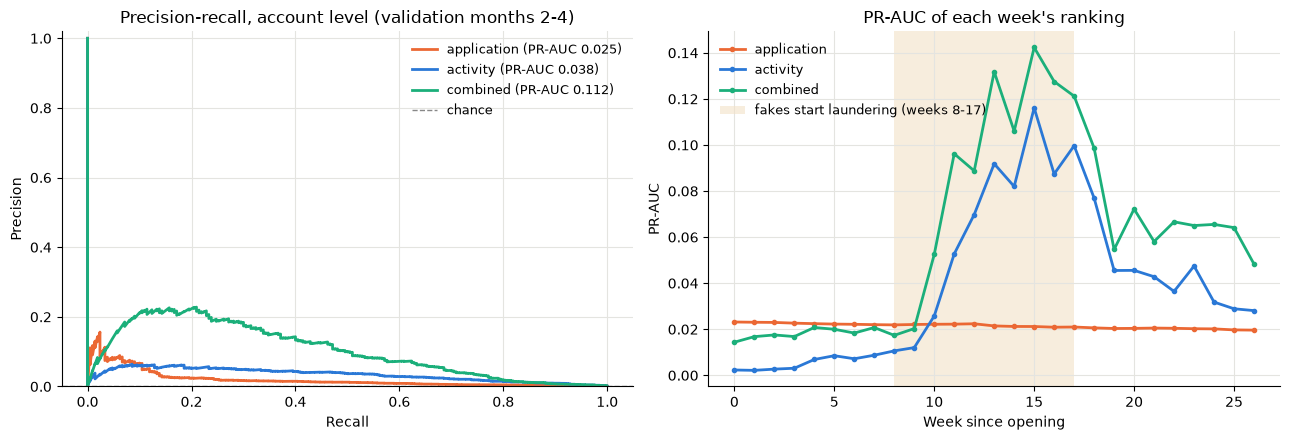

In [7]:
def acc_scores(v):
    o = oof[oof.view == v]
    return o.groupby("account_id").agg(y=("mule_by_day", "max"), s=("score", "max"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for v in COLORS:
    a = acc_scores(v); p, r, _ = precision_recall_curve(a["y"], a["s"])
    axes[0].plot(r, p, color=COLORS[v], lw=2, label=f"{v} (PR-AUC {folds.loc[folds.view == v, 'acc_pr_auc'].mean():.3f})")
axes[0].axhline(acc_scores("combined")["y"].mean(), color="#888", ls="--", lw=1, label="chance")
axes[0].set(xlabel="Recall", ylabel="Precision", title="Precision-recall, account level (validation months 2-4)", ylim=(0, 1.02))
axes[0].legend(frameon=False, fontsize=9)

wk_rows = []
for (v, w), g in oof.groupby(["view", "weeks_since_open"]):
    if 0 < g.mule_by_day.sum() < len(g):
        wk_rows.append({"view": v, "week": w, "pr_auc": average_precision_score(g.mule_by_day, g.score)})
wkdf = pd.DataFrame(wk_rows)
for v in COLORS:
    t = wkdf[wkdf.view == v]; axes[1].plot(t.week, t.pr_auc, color=COLORS[v], lw=2, marker="o", ms=3, label=v)
axes[1].axvspan(8, 17, color="#f3e2c7", alpha=0.6, lw=0, label="fakes start laundering (weeks 8-17)")
axes[1].set(xlabel="Week since opening", ylabel="PR-AUC", title="PR-AUC of each week's ranking")
axes[1].legend(frameon=False, fontsize=9)
for ax in axes:
    ax.spines[["top", "right"]].set_visible(False); ax.grid(color="#e4e4e0")
fig.tight_layout(); fig.savefig(REPORT / "01_pr_and_by_week.png", dpi=130); plt.show()

## 6. Coefficients (combined view)

Every input is standardised, so coefficient sizes are comparable: a positive coefficient raises the odds of
"mule", a negative one lowers them. One standard-deviation step multiplies the odds by $e^{\beta}$.
Mean of the three folds; the 15 largest in absolute size.

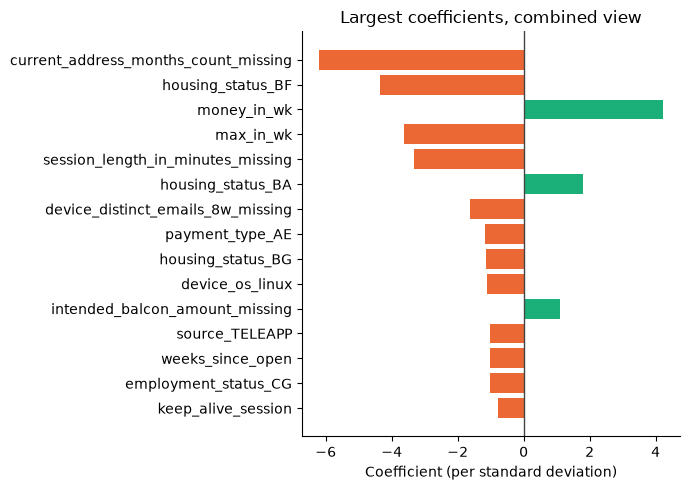

,coef,odds_ratio
current_address_months_count_missing,-6.202,0.002
housing_status_BF,-4.364,0.013
money_in_wk,4.218,67.872
max_in_wk,-3.633,0.026
session_length_in_minutes_missing,-3.315,0.036
housing_status_BA,1.809,6.103
device_distinct_emails_8w_missing,-1.621,0.198
payment_type_AE,-1.169,0.311
housing_status_BG,-1.143,0.319
device_os_linux,-1.100,0.333


In [8]:
c = (coefs[coefs.view == "combined"].groupby("feature")["coef"].mean()
     .sort_values(key=np.abs, ascending=False).head(15))
c.index = [i.split("__", 1)[-1] for i in c.index]
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(c.index[::-1], c.values[::-1], color=["#1baf7a" if v > 0 else "#eb6834" for v in c.values[::-1]])
ax.axvline(0, color="#444", lw=1)
ax.set(xlabel="Coefficient (per standard deviation)", title="Largest coefficients, combined view")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(REPORT / "02_coefficients.png", dpi=130); plt.show()
c.to_frame("coef").assign(odds_ratio=np.exp(c)).round(3)

## 7. Compare with LightGBM and save

`05_lgbm_baseline.ipynb` has to be run on the same data

In [9]:
lgbm_path = Path(f"outputs/modelling/models/{RUN}/lgbm_baseline/metrics_by_fold.csv")
key = ["acc_pr_auc", "acc_roc_auc", "acc_top_1%_precision", "acc_top_1%_recall", "acc_top_1%_f1"]
both = [folds.groupby("view")[key].mean().assign(model="logistic")]
if lgbm_path.exists():
    both.append(pd.read_csv(lgbm_path).groupby("view")[key].mean().assign(model="lightgbm"))
else:
    print("no LightGBM results yet for this data folder - run 05_lgbm_baseline.ipynb first")
compare = pd.concat(both).reset_index().set_index(["view", "model"]).sort_index().rename(columns=COLS)
display(compare.round(3)) if "ipykernel" in sys.modules else print(compare.round(3))

folds.to_csv(REPORT / "metrics_by_fold.csv", index=False)
coefs.to_csv(REPORT / "coefficients.csv", index=False)
wkdf.to_csv(REPORT / "oof_by_week.csv", index=False)
compare.to_csv(REPORT / "compare_with_lgbm.csv")
print(f"saved to {REPORT} ({time.time() - t0:.0f}s)")

PR-AUC  ROC-AUC  P top 1%  R top 1%  F1 top 1%
view        model                                                   
activity    lightgbm   0.730    0.989     0.181     0.871      0.300
            logistic   0.038    0.919     0.056     0.267      0.092
application lightgbm   0.011    0.743     0.020     0.092      0.033
            logistic   0.025    0.799     0.033     0.156      0.054
combined    lightgbm   0.256    0.953     0.112     0.526      0.185
            logistic   0.112    0.931     0.105     0.501      0.173

saved to outputs/modelling/models/v1_full/logreg_baseline (99s)


# Report:
- PR-AUC shows that signals from `activity` related features are non-linear, so lightGBM is a decisive model (19x better than baseline)
- On `application` features, logistic slightly beats lightGBM, suggesting model is weak and additive and a simpler model generalises better